# KKT Conditions & Planar Duality

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize
from sympy import symbols, diff, solve, simplify, lambdify
import networkx as nx
from networkx.algorithms import planarity

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print("All libraries imported successfully!")

All libraries imported successfully!


---
## 1. KKT Conditions in Practice

### Problem Statement
Consider minimizing the squared distance from $(3, 2)$ subject to two linear inequality constraints:

$$\min_{x_1, x_2} \; f(x_1, x_2) = (x_1 - 3)^2 + (x_2 - 2)^2$$
$$\text{subject to:} \quad g_1(x_1, x_2) = x_1 + x_2 - 3 \le 0, \qquad g_2(x_1, x_2) = x_1 - 2.5 \le 0$$

Recall the **4 KKT Conditions** for a candidate $(x^*, \lambda^*)$:
1. **Stationarity:** $\nabla_x \mathcal{L}(x^*, \lambda^*) = \nabla f(x^*) + \sum_i \lambda_i^* \nabla g_i(x^*) = 0$
2. **Primal Feasibility:** $g_i(x^*) \le 0$ for all $i$
3. **Dual Feasibility:** $\lambda_i^* \ge 0$ for all $i$
4. **Complementary Slackness:** $\lambda_i^* g_i(x^*) = 0$ for all $i$

### 1.1 Symbolic KKT Solver with `sympy`

In theory, you solve KKT by checking all active/inactive combinations of constraints. With `sympy`, we can encode Stationarity + Complementary Slackness as a single polynomial system, let `solve()` enumerate all candidate points, and then filter by **Primal** and **Dual Feasibility** in a `pandas` table.

In [2]:
x1, x2, l1, l2 = symbols("x1 x2 l1 l2", real=True)

f = (x1 - 3)**2 + (x2 - 2)**2
g1 = x1 + x2 - 3     # <= 0
g2 = x1 - 2.5        # <= 0

# Build the Lagrangian
L = f + l1 * g1 + l2 * g2

# 1. Stationarity: grad_x L = 0
grad_L = [simplify(diff(L, x1)), simplify(diff(L, x2))]
print("Stationarity equations:", grad_L)

# Solve Stationarity + Complementary Slackness (l_i * g_i = 0)
kkt_system = [grad_L[0], grad_L[1], l1 * g1, l2 * g2]
candidates = solve(kkt_system, [x1, x2, l1, l2], dict=True)

# Evaluate Primal & Dual Feasibility for every candidate
rows = []
for i, sol in enumerate(candidates, start=1):
    g1_val = float(g1.subs(sol))
    g2_val = float(g2.subs(sol))
    l1_val = float(sol[l1])
    l2_val = float(sol[l2])
    primal_ok = (g1_val <= 1e-9) and (g2_val <= 1e-9)
    dual_ok = (l1_val >= -1e-9) and (l2_val >= -1e-9)
    rows.append({
        "Candidate": f"Case {i}",
        "x1": float(sol[x1]),
        "x2": float(sol[x2]),
        "lambda_1": l1_val,
        "lambda_2": l2_val,
        "g1(x)": g1_val,
        "g2(x)": g2_val,
        "f(x)": float(f.subs(sol)),
        "Primal Feasible": primal_ok,
        "Dual Feasible": dual_ok,
        "Valid KKT Point": primal_ok and dual_ok,
    })

kkt_df = pd.DataFrame(rows)
kkt_df

Stationarity equations: [l1 + l2 + 2*x1 - 6, l1 + 2*x2 - 4]


,Candidate,x1,x2,lambda_1,lambda_2,g1(x),g2(x),f(x),Primal Feasible,Dual Feasible,Valid KKT Point
0,Case 1,3.0,2.0,0.0,0.0,2.0,0.5,0.00,False,True,False
1,Case 2,2.5,2.0,0.0,1.0,1.5,0.0,0.25,False,True,False
2,Case 3,2.0,1.0,2.0,0.0,0.0,-0.5,2.00,True,True,True
3,Case 4,2.5,0.5,3.0,-2.0,0.0,0.0,2.50,True,False,False


**What just happened?**
- `sympy.solve` found all 4 active-set combinations!
- **Cases 1 & 2** fail **Primal Feasibility** ($g_1 > 0$ or $g_2 > 0$).
- **Case 4** is primal feasible (both constraints active at $(2.5, 0.5)$), **but** $\lambda_2 = -2 < 0$, failing **Dual Feasibility**!
- **Case 3** at $(2.0, 1.0)$ with $\lambda_1 = 2.0, \lambda_2 = 0.0$ is the unique valid KKT point: $g_1$ is active ($g_1 = 0, \lambda_1 > 0$) and $g_2$ is inactive ($g_2 = -0.5 < 0, \lambda_2 = 0$).

### 1.2 Numerical Optimization & Verification with `scipy.optimize.minimize`

For real-world problems with dozens of variables or nonlinear constraints, symbolic `solve()` is too slow. Instead, we use `lambdify` to turn `sympy` expressions into fast NumPy functions and pass them to `scipy.optimize.minimize` (using `SLSQP`).

> **Watch out for sign conventions!**  
> Standard KKT textbook notation uses $g(x) \le 0$, whereas `scipy`'s `'ineq'` constraints require $c(x) \ge 0$ (so we pass `-g(x)`).

In [3]:
# Convert symbolic expressions to fast numerical callables
f_num = lambdify((x1, x2), f, "numpy")
grad_f_num = lambdify((x1, x2), [diff(f, x1), diff(f, x2)], "numpy")
g1_num = lambdify((x1, x2), g1, "numpy")
g2_num = lambdify((x1, x2), g2, "numpy")

constraints = [
    {"type": "ineq", "fun": lambda x: -g1_num(x[0], x[1])},  # -g1(x) >= 0
    {"type": "ineq", "fun": lambda x: -g2_num(x[0], x[1])},  # -g2(x) >= 0
]

res = minimize(
    fun=lambda x: f_num(x[0], x[1]),
    x0=np.array([0.0, 0.0]),
    jac=lambda x: np.array(grad_f_num(x[0], x[1])),
    method="SLSQP",
    constraints=constraints,
)

x_opt = res.x
grad_f_opt = np.array(grad_f_num(x_opt[0], x_opt[1]))
grad_g1 = np.array([1.0, 1.0])  # active constraint gradient

# Estimate active multiplier from -grad_f = lambda_1 * grad_g1
lambda1_est = np.linalg.lstsq(grad_g1[:, None], -grad_f_opt, rcond=None)[0][0]

comparison = pd.DataFrame([
    {"Method": "Symbolic (SymPy)", "x1": 2.0, "x2": 1.0, "f(x*)": 2.0, "lambda_1": 2.0},
    {"Method": "Numerical (SLSQP)", "x1": x_opt[0], "x2": x_opt[1], "f(x*)": res.fun, "lambda_1": lambda1_est},
])
print("SLSQP converged:", res.success)
comparison

SLSQP converged: True


,Method,x1,x2,f(x*),lambda_1
0,Symbolic (SymPy),2.0,1.0,2.0,2.0
1,Numerical (SLSQP),2.0,1.0,2.0,2.0


### 1.3 Geometric Intuition: Feasible Region & Normal Cone

Why must $\nabla f(x^*) + \lambda_1 \nabla g_1(x^*) = 0$ with $\lambda_1 \ge 0$?  
Geometrically, at the optimum $x^*$, the descent direction $-\nabla f(x^*)$ must point **directly into the infeasible region** along $\nabla g_1(x^*)$—otherwise, you could slide along the boundary and reduce $f$ further!

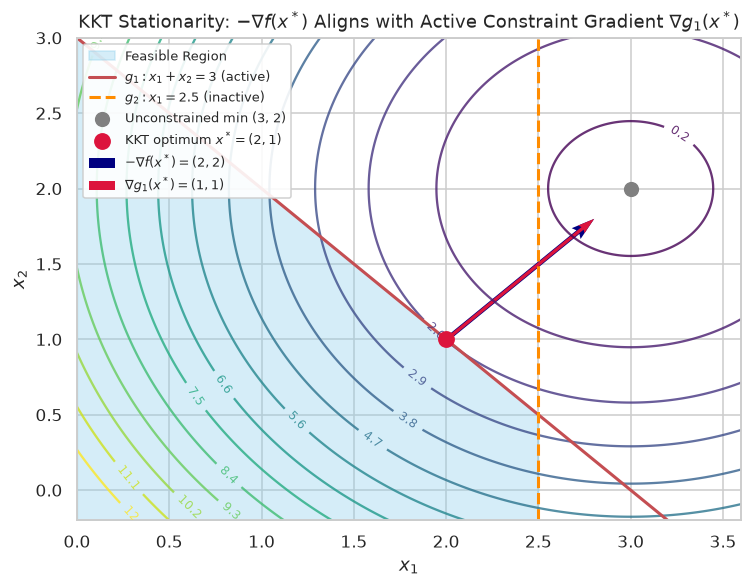

In [4]:
x1_grid = np.linspace(0.0, 3.8, 300)
x2_grid = np.linspace(-0.2, 3.2, 300)
X1, X2 = np.meshgrid(x1_grid, x2_grid)
Z = f_num(X1, X2)

fig, ax = plt.subplots(figsize=(7, 5.5))

# Objective contours
contours = ax.contour(X1, X2, Z, levels=np.linspace(0.2, 12, 14), cmap="viridis", alpha=0.8)
ax.clabel(contours, inline=True, fontsize=8, fmt="%.1f")

# Shade feasible region: x1 + x2 <= 3 and x1 <= 2.5
x_fill = np.linspace(0.0, 2.5, 200)
y_top = 3.0 - x_fill
ax.fill_between(x_fill, -0.2, y_top, color="skyblue", alpha=0.35, label="Feasible Region")

# Constraint boundaries
ax.plot(x1_grid, 3.0 - x1_grid, "r-", lw=2, label=r"$g_1: x_1 + x_2 = 3$ (active)")
ax.axvline(2.5, color="darkorange", ls="--", lw=2, label=r"$g_2: x_1 = 2.5$ (inactive)")

# Unconstrained vs Constrained optima
ax.scatter([3.0], [2.0], color="gray", s=80, zorder=5, label="Unconstrained min (3, 2)")
ax.scatter([x_opt[0]], [x_opt[1]], color="crimson", s=100, zorder=6, label=r"KKT optimum $x^* = (2, 1)$")

# Gradient vectors at x* (scaled for visibility)
ax.quiver(x_opt[0], x_opt[1], -grad_f_opt[0], -grad_f_opt[1],
          angles="xy", scale_units="xy", scale=2.5, color="navy", width=0.007,
          label=r"$-\nabla f(x^*) = (2, 2)$")
ax.quiver(x_opt[0], x_opt[1], grad_g1[0], grad_g1[1],
          angles="xy", scale_units="xy", scale=1.25, color="crimson", width=0.005,
          label=r"$\nabla g_1(x^*) = (1, 1)$")

ax.set_xlim(0.0, 3.6)
ax.set_ylim(-0.2, 3.0)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("KKT Stationarity: $-\\nabla f(x^*)$ Aligns with Active Constraint Gradient $\\nabla g_1(x^*)$")
ax.legend(loc="upper left", fontsize=8.5, framealpha=0.9)
plt.tight_layout()
plt.show()

---
## Part 2: Planar Graphs & Planar Duality in Practice

### 2.1 Checking Planarity & Euler's Formula

A graph $G$ is **planar** if it can be drawn in the 2D plane without any edges crossing. In `networkx`, `planarity.check_planarity(G)` runs in linear time $O(V)$ and returns `(is_planar, certificate)`:
- If `True`: `certificate` is a **`PlanarEmbedding`** (storing the cyclic clockwise/counter-clockwise neighbor order at every vertex).
- If `False`: `certificate` is a **Kuratowski subgraph** (a subdivision of $K_5$ or $K_{3,3}$) proving non-planarity.

In [5]:
# Build a simple 6-node planar graph (2x3 grid + one diagonal)
G = nx.Graph()
G.add_edges_from([
    (0, 1), (1, 2),
    (3, 4), (4, 5),
    (0, 3), (1, 4), (2, 5),
    (0, 4),  # diagonal splitting left square into two triangles
])

is_planar_G, embedding = planarity.check_planarity(G)
print(f"Is G planar? {is_planar_G} | Certificate type: {type(embedding).__name__}")

# Contrast with K5 (the smallest complete non-planar graph)
K5 = nx.complete_graph(5)
is_planar_K5, k5_cert = planarity.check_planarity(K5, counterexample=True)
print(f"Is K5 planar? {is_planar_K5} | Certificate edges: {list(k5_cert.edges())[:5]}...")
if not is_planar_K5:
    print(f"Kuratowski certificate edges: {list(k5_cert.edges())}")

Is G planar? True | Certificate type: PlanarEmbedding
Is K5 planar? False | Certificate edges: [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2)]...
Kuratowski certificate edges: [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]


### 2.2 Extracting Faces & Building the Planar Dual $G^*$

A `PlanarEmbedding` represents each undirected edge $\{u, v\}$ as two opposite **half-edges** $(u, v)$ and $(v, u)$. Walking around a face with `embedding.traverse_face(u, v)` visits all vertices on that face's boundary!

From the faces, we construct the **planar dual** $G^*$:
- **Dual Vertices ($V^*$):** One node per face of $G$ (including the unbounded outer face!).
- **Dual Edges ($E^*$):** Each primal edge $\{u, v\}$ separates two faces (one on half-edge $(u, v)$, one on $(v, u)$), so it becomes an edge between those two faces in $G^*$.

> **Important practical detail:** Two faces can share *more than one* primal edge (creating parallel edges in $G^*$), and a bridge edge has the same face on both sides (creating a self-loop). Therefore, $G^*$ should always be stored as an `nx.MultiGraph()`!

In [6]:
# 1. Extract all faces using half-edge traversal
visited_half_edges = set()
faces = []
for u, v in embedding.edges():
    if (u, v) not in visited_half_edges:
        face_nodes = embedding.traverse_face(u, v, mark_half_edges=visited_half_edges)
        faces.append(face_nodes)

# Map each directed half-edge (a, b) -> its face index
half_edge_to_face = {}
for f_id, face in enumerate(faces):
    for i in range(len(face)):
        a = face[i]
        b = face[(i + 1) % len(face)]
        half_edge_to_face[(a, b)] = f_id

# 2. Construct the dual MultiGraph G*
G_dual = nx.MultiGraph()
for f_id, face in enumerate(faces):
    G_dual.add_node(f_id, cycle=face, length=len(face))

for u, v in G.edges():
    f_left = half_edge_to_face[(u, v)]
    f_right = half_edge_to_face[(v, u)]
    G_dual.add_edge(f_left, f_right, primal_edge=(u, v))

# 3. Verify Euler's Formula (V - E + F = 2) and Primal-Dual correspondence
V, E, F = G.number_of_nodes(), G.number_of_edges(), len(faces)
print(f"Euler's Formula Check: V - E + F = {V} - {E} + {F} = {V - E + F}")

face_summary = pd.DataFrame([
    {
        "Dual Node (Face ID)": f_id,
        "Boundary Cycle": " -> ".join(map(str, data["cycle"])),
        "Face Length (Edges)": data["length"],
        "Dual Degree in G*": G_dual.degree(f_id),
    }
    for f_id, data in G_dual.nodes(data=True)
])
face_summary

Euler's Formula Check: V - E + F = 6 - 8 + 4 = 2


,Dual Node (Face ID),Boundary Cycle,Face Length (Edges),Dual Degree in G*
0,0,0 -> 4 -> 5 -> 2 -> 1,5,5
1,1,0 -> 3 -> 4,3,3
2,2,0 -> 1 -> 4 -> 3,4,4
3,3,1 -> 2 -> 5 -> 4,4,4


### 2.3 Visualizing Primal $G$ and Dual $G^*$ Together

Let's draw $G$ with clean coordinates and place each dual vertex at the centroid of its face—placing the outer face node cleanly outside the drawing.

**Why do we care about $G^*$ in practice?**
1. **Min-Cut $\leftrightarrow$ Shortest Cycle:** Finding a minimum $s$-$t$ cut in a planar network $G$ reduces to finding a **shortest cycle** in the dual $G^*$ (used in image segmentation and VLSI routing).
2. **Map Coloring:** 4-coloring the faces of a planar map $G$ is equivalent to 4-coloring the **vertices** of $G^*$.
3. **Duality of Spanning Trees:** Every spanning tree $T \subseteq E$ has a complementary dual spanning tree $E^* \setminus T^*$!

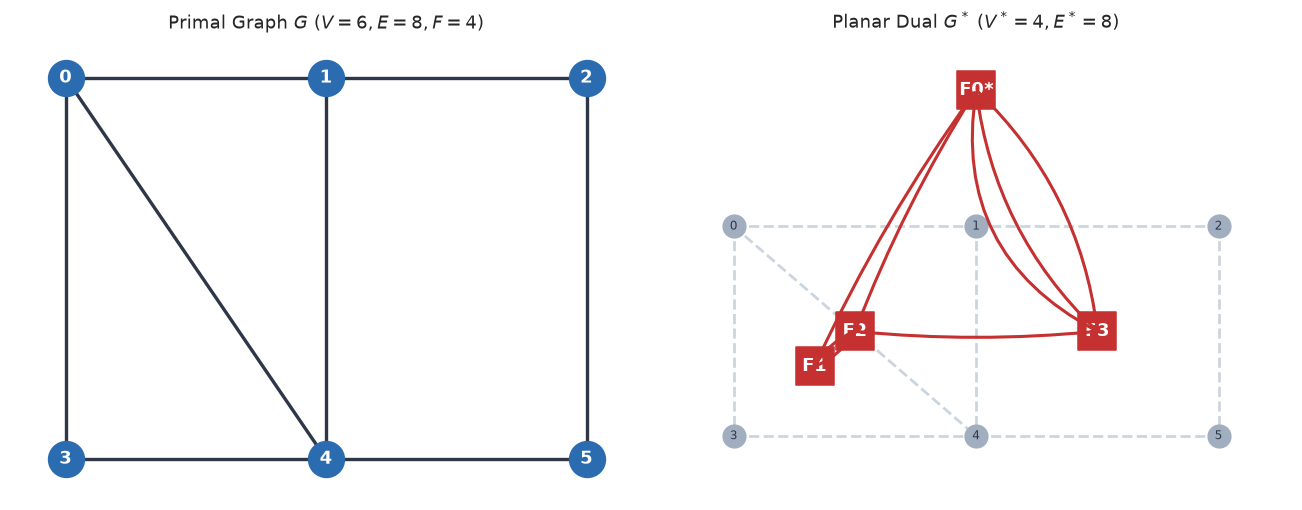

In [7]:
# Clean grid coordinates for G so faces are visually obvious
pos_G = {
    0: (0.0, 1.0), 1: (1.0, 1.0), 2: (2.0, 1.0),
    3: (0.0, 0.0), 4: (1.0, 0.0), 5: (2.0, 0.0),
}

# Identify outer face (longest cycle here) and compute dual node positions
outer_face_id = max(G_dual.nodes(), key=lambda f: G_dual.nodes[f]["length"])
pos_dual = {}
for f_id, data in G_dual.nodes(data=True):
    if f_id == outer_face_id:
        pos_dual[f_id] = (1.0, 1.65)  # place outer face node clearly above
    else:
        pts = np.array([pos_G[n] for n in data["cycle"]])
        pos_dual[f_id] = tuple(pts.mean(axis=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: Primal Graph G
nx.draw_networkx(
    G, pos=pos_G, ax=axes[0],
    node_color="#2b6cb0", font_color="white",
    node_size=550, edge_color="#2d3748", width=2.2, font_weight="bold"
)
axes[0].set_title(f"Primal Graph $G$ ($V={V}, E={E}, F={F}$)")
axes[0].axis("off")

# Right: Primal (faint) + Dual G* (highlighted)
nx.draw_networkx_edges(G, pos=pos_G, ax=axes[1], edge_color="#cbd5e0", width=1.8, style="dashed")
nx.draw_networkx_nodes(G, pos=pos_G, ax=axes[1], node_color="#a0aec0", node_size=220)
nx.draw_networkx_labels(G, pos=pos_G, ax=axes[1], font_size=8, font_color="#2d3748")

# Draw dual nodes and edges (curving parallel edges slightly via connectionstyle)
nx.draw_networkx_nodes(G_dual, pos=pos_dual, ax=axes[1], node_color="#c53030", node_size=600, node_shape="s")
dual_labels = {f_id: f"F{f_id}" + ("*" if f_id == outer_face_id else "") for f_id in G_dual.nodes()}
nx.draw_networkx_labels(G_dual, pos=pos_dual, labels=dual_labels, ax=axes[1], font_color="white", font_weight="bold")

for u, v, key in G_dual.edges(keys=True):
    if G_dual.number_of_edges(u, v) > 1:
        rad = 0.18 * (1 if key % 2 == 0 else -1) * (1 + key // 2)
    else:
        rad = 0.05
    axes[1].annotate(
        "", xy=pos_dual[v], xytext=pos_dual[u],
        arrowprops=dict(arrowstyle="-", color="#c53030", lw=2.0, connectionstyle=f"arc3,rad={rad}"),
    )

axes[1].set_title(f"Planar Dual $G^*$ ($V^*={G_dual.number_of_nodes()}, E^*={G_dual.number_of_edges()}$)")
axes[1].set_xlim(-0.3, 2.3)
axes[1].set_ylim(-0.3, 1.9)
axes[1].axis("off")

plt.tight_layout()
plt.show()

---
## 3. Wrap-Up & Try-It-Yourself Exercises


**Key Takeaways:**
- **KKT in Practice:** Use `sympy` to derive exact gradients and understand active-set cases; use `scipy.optimize.minimize` with `lambdify` for fast numerical solving (and always double-check constraint sign conventions!).
- **Planar Dual in Practice:** `planarity.check_planarity(G)` gives a `PlanarEmbedding` whose half-edges (`traverse_face`) let you build the dual `MultiGraph` $G^*$ in ~15 lines of Python.

### Exercises
1. **Nonlinear KKT:** Change $g_2(x_1, x_2)$ to $x_1^2 + x_2^2 - 4 \le 0$. Re-run Section 1.1 & 1.2—which constraint is active now, and what happens to $\lambda_1, \lambda_2$?
2. **Planar Dual Bridge Test:** Add a dangling node `6` connected only to `2` via edge `(2, 6)` in `G`. Re-run Section 2.2—why does `G_dual` now contain a **self-loop**?